# Importing packages and defining functions

In [1]:
import xarray as xr
import numpy as np

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

from eofs.xarray import Eof
from eofs.examples import example_data_path

In [2]:
# Calculates numeric seconds since first timestamp (keeps numbers small)
def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

In [3]:
# Point by point detrending of the data:
# 1) Fit a regression to the trend (time vs signal) at each point
# 2) Use the regression to remove the trend at each point
def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj[time_dim], time_dim)
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})                          # one chunk along time
        mask = da.notnull()
        t_b = t.broadcast_like(da)                                 # (time, ...) # Putting time as seconds into a dataarray like da
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True) # Average of seconds over time dimension (skipping nans)
        tc = t_b - t_mean_valid                                    # centered time per point
        
        num = (da * tc).sum(time_dim, skipna=True)  # multiply sst by centered time and add over time (skipping nans) at each point
        den = (tc**2).sum(time_dim, skipna=True)    # squaring centered time and add over time (skipping nans) at each point
        slope = xr.where(den > 0, num / den, 0.0)   # divides num/den when den>0, else plugs in zero
        ybar  = da.mean(time_dim, skipna=True)      # taking the average in SST over time (skipping nans) at each point
        trend = slope * (t_b - t_mean_valid) + ybar # linear regression
        return (da - trend).astype("float32")       # removing trend from data at each point
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj) # map to dataset if input at dataset, else put dataarray into function


In [4]:
# Standardized the data so that physical units of one dataset don't outweight another
# AKA don't want large variations in one variable to weight more than variables with lower scales of variations
# Computed by the Z-score (anomolies weighted by std away from the mean)
def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    Z-score: how many stds a data point is from the mean of its dataset
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)}) # choose over time period if needed
    key = f"{time_dim}.month"                                                             # creates string: 'valid_time.month'

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True) # take average at each point by month over all years (skipping nans)
    anom = detr.groupby(key) - clim_mean                          # subtract mean at each gridpoint for each month

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof) # calculating std at each grid point, per month, over all years (skipping nans)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan) # anywhere where std is greater than eps, set to nan
    
    z = anom.groupby(key) / safe_std # calculating the z score
    return anom, z

In [5]:
# Function to unstandardize the data
def unpack(z_da,
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "valid_time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True) 

    anom = z.groupby(key)*safe_std # Multiplying standardized data by std to get the anomolies
    reconst_detr = anom.groupby(key) + clim_mean # Adding the mean back to the anomlies to get the detrended data
    return(reconst_detr)

In [6]:
# Function to add the trend back into the data
def linear_retrend(og_da, reconstruction_detr, time_dim="valid_time"):
    t = _time_as_float(og_da[time_dim], time_dim)

    da = og_da.sortby(time_dim).astype("float32")
    if hasattr(da.data, "chunks"):
        da = da.chunk({time_dim: -1})  
    mask = da.notnull()                               
    t_b = t.broadcast_like(da)                         
    t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True) 
    tc = t_b - t_mean_valid                          
    
    num = (da * tc).sum(time_dim, skipna=True) 
    den = (tc**2).sum(time_dim, skipna=True) 
    slope = xr.where(den > 0, num / den, 0.0) 
    ybar  = da.mean(time_dim, skipna=True) 
    trend = slope * (t_b - t_mean_valid) + ybar 
    return (reconstruction_detr + trend).astype("float32") # add the trend into the detrended data to return original data

# Reading in, Detrending, and Standardizing Monthly Anomolies of the data

In [8]:
ds = xr.open_dataset('/data/keeling/a/kheimes2/more_space/Grad_Classes/ATMS523_Repos/M4_Project_DataV2.nc')
ds['mask_sst'] = ds.sst.where(ds.lsm==0)
ds

<xarray.Dataset> Size: 3GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver      (valid_time) <U4 9kB ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB ...
    lsm         (valid_time, latitude, longitude) float32 829MB 0.9839 ... 0....
    tcwv        (valid_time, latitude, longitude) float32 829MB ...
    mask_sst    (valid_time, latitude, longitude) float32 829MB nan nan ... nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-13T19:42 GRIB to CDM+CF via cfgrib-0.9.1...

In [ ]:
ds = ds.chunk({"valid_time": -1})

detr = linear_detrend(ds[["mask_sst", "tcwv"]], time_dim="valid_time") # linearly detrended data
anom, z = monthly_anom_and_z(detr, time_dim="valid_time")

print(type(z), list(z.data_vars))

<class 'xarray.core.dataset.Dataset'> ['mask_sst', 'tcwv']


/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


# 3) EOF Analysis
- Perform on SST anomolies 
- Plot map of first 5 EOFs

In [ ]:
dims = ('time', 'latitude', 'longitude')
time = z.valid_time.values
latitude = z.latitude.values
longitude = z.longitude.values
coords = {'time': time, 'latitude': latitude, 'longitude':longitude}
sst_stand_da = xr.DataArray(z.mask_sst.values, coords=coords, dims=dims)
sst_stand_da

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


<xarray.DataArray (time: 552, latitude: 521, longitude: 721)> Size: 829MB
array([[[        nan,         nan,         nan, ...,  1.6342226 ,
          1.572493  ,  1.4920446 ],
        [        nan,         nan,         nan, ...,  1.5488622 ,
          1.4206866 ,  1.2698191 ],
        [        nan,         nan,         nan, ...,  1.4793197 ,
          1.3204501 ,  1.1469797 ],
        ...,
        [-0.6567273 , -0.6530516 , -0.64502966, ...,         nan,
                 nan,         nan],
        [-1.8703427 , -1.8472561 , -1.8117931 , ...,         nan,
                 nan,         nan],
        [-1.5652232 , -1.5522606 , -1.5423368 , ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  1.6717054 ,
          1.6703893 ,  1.6690979 ],
        [        nan,         nan,         nan, ...,  1.6689988 ,
          1.657511  ,  1.6413393 ],
        [        nan,         nan,         nan, ...,  1.661698  ,
          1.6377907 ,  1.6078293 ],
...
        [-1.1571009 , -1.2054849 , -1.23667   , ...,         nan,
                 nan,         nan],
        [-1.4559864 , -1.444183  , -1.4325109 , ...,         nan,
                 nan,         nan],
        [-1.661802  , -1.6554738 , -1.6562634 , ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ..., -1.3214455 ,
         -1.0954697 , -0.87296104],
        [        nan,         nan,         nan, ..., -0.8828695 ,
         -0.73471177, -0.60664266],
        [        nan,         nan,         nan, ..., -0.8415293 ,
         -0.71858203, -0.60837775],
        ...,
        [ 1.0555977 ,  0.9502642 ,  0.83527505, ...,         nan,
                 nan,         nan],
        [ 1.3448454 ,  1.2572036 ,  1.1633053 , ...,         nan,
                 nan,         nan],
        [ 1.5693809 ,  1.5565435 ,  1.6694195 , ...,         nan,
                 nan,         nan]]], shape=(552, 521, 721), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude   (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude  (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/data/keeling/a/kheim

In [13]:
# Create an EOF solver to do the EOF analysis
# Square-root of cosine of latitude weights are applied before the computation of EOFs.
coslat = np.cos(np.deg2rad(sst_stand_da.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(sst_stand_da, weights=wgts)

In [29]:
# eofs_5 = solver.eofsAsCorrelation(neofs=5)
# pc5 = solver.pcs(npcs=5, pcscaling=1)
eofs_5 = solver.eofsAsCorrelation()
pc5 = solver.pcs()

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


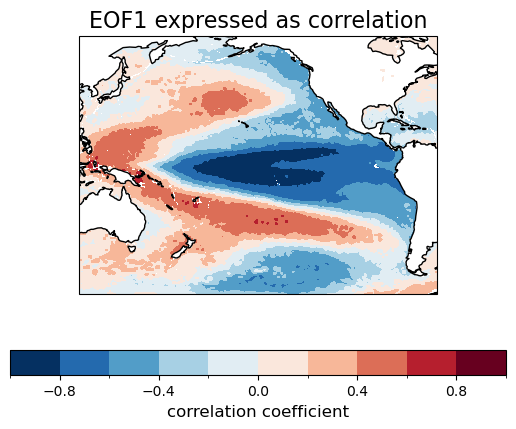

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


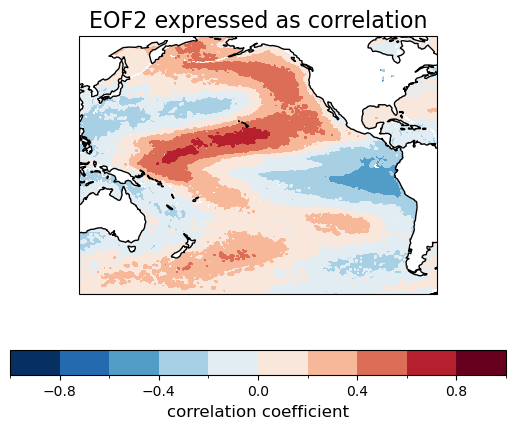

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


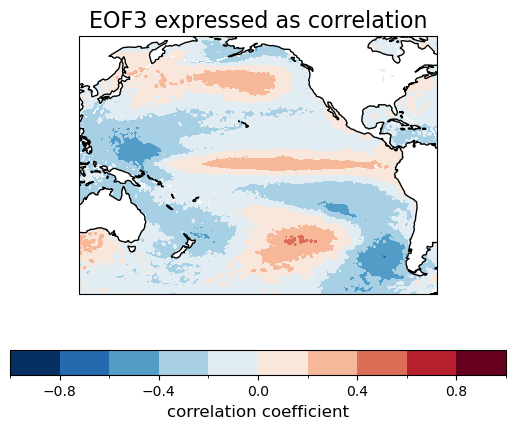

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


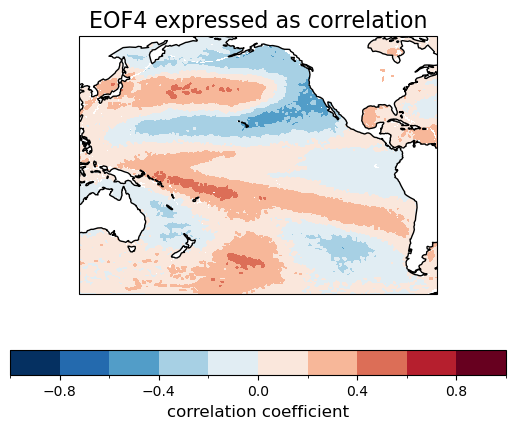

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


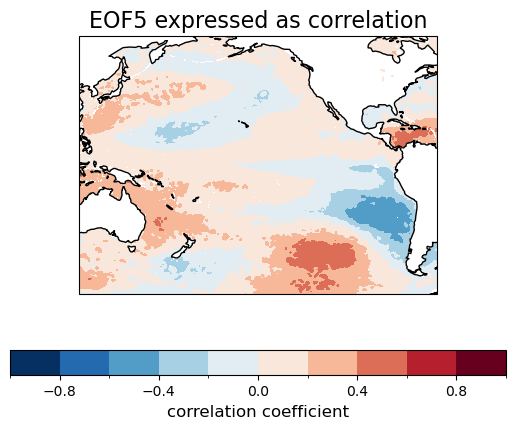

In [30]:
clevs = np.linspace(-1, 1, 11)
for n in range(0,5):
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
    fill = eofs_5[n].plot.contourf(ax=ax, levels=clevs, cmap=plt.cm.RdBu_r,
                                add_colorbar=False, transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
    cb = plt.colorbar(fill, orientation='horizontal')
    cb.set_label('correlation coefficient', fontsize=12)
    ax.set_title('EOF'+str(n+1)+' expressed as correlation', fontsize=16)
    plt.show()

# 4) Plot of percent variance explained by first 10 EOFs

In [31]:
varfrac = solver.varianceFraction()

(5.326431163537107e-14, 19.515411376953125)

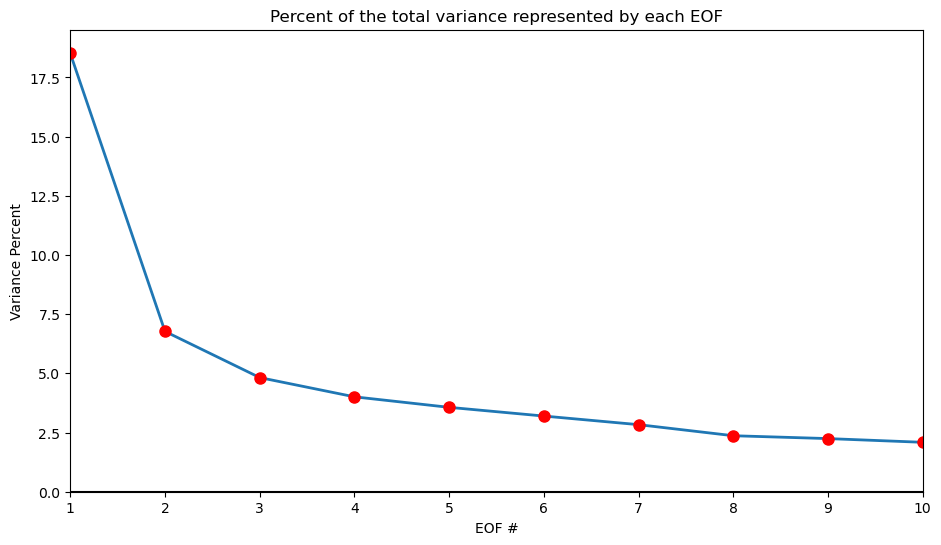

In [32]:
# Plot the fraction of variance explained by each EOF
plt.figure(figsize=(11,6))
eof_num = range(1, 11)
plt.plot(eof_num, varfrac[0:10]*100, linewidth=2)
plt.plot(eof_num, varfrac[0:10]*100, linestyle='None', marker="o", color='r', markersize=8)
plt.axhline(0, color='k')
plt.xticks(range(1, 16))
plt.title('Percent of the total variance represented by each EOF')
plt.xlabel('EOF #')
plt.ylabel('Variance Percent')
plt.xlim(1, 10)
plt.ylim(np.min(varfrac)*100, np.max(varfrac)*100+1)

# 5) 
- Reconstruct SST field using first 5 EOFs 
- Plot a map of Pearson's correlation coefficient (xarray.corr) of:

    a) reconstructed monthly times series 

    b) observed sst time series

In [33]:
reconst_z = solver.reconstructedField(5)
reconst_z = reconst_z.rename({'time':'valid_time'})

reconst_detr = unpack(reconst_z, detr.mask_sst, time_dim="valid_time")

reconst_sst = linear_retrend(ds.mask_sst, reconst_detr.mask_sst, time_dim="valid_time")
reconst_sst

<xarray.DataArray (valid_time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<astype, shape=(552, 521, 721), dtype=float32, chunksize=(1, 521, 721), chunktype=numpy.ndarray>
Coordinates:
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


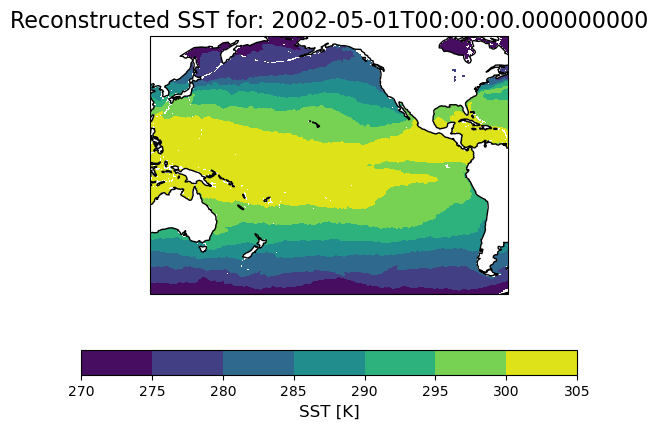

In [34]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = reconst_sst[280,:,:].plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('SST [K]', fontsize=12)
ax.set_title('Reconstructed SST for: '+str(reconst_sst.valid_time.values[280]), fontsize=16)
plt.show()

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


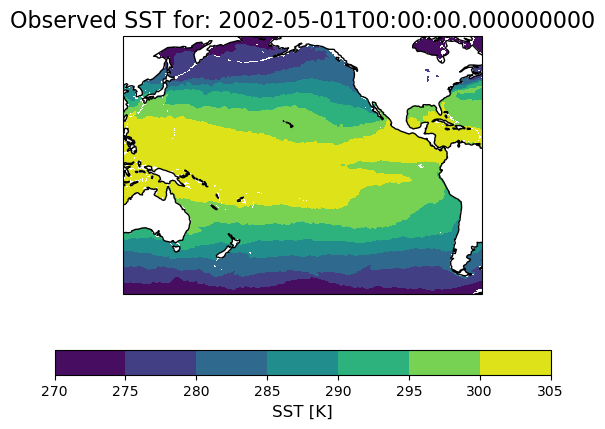

In [35]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = ds.mask_sst[280,:,:].plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('SST [K]', fontsize=12)
ax.set_title('Observed SST for: '+str(ds.valid_time.values[280]), fontsize=16)
plt.show()

In [36]:
cc_obs = xr.corr(reconst_sst, ds['mask_sst'], dim='valid_time')

In [37]:
print(np.min(cc_obs).values, np.max(cc_obs).values)

0.9999192 1.0000701


/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


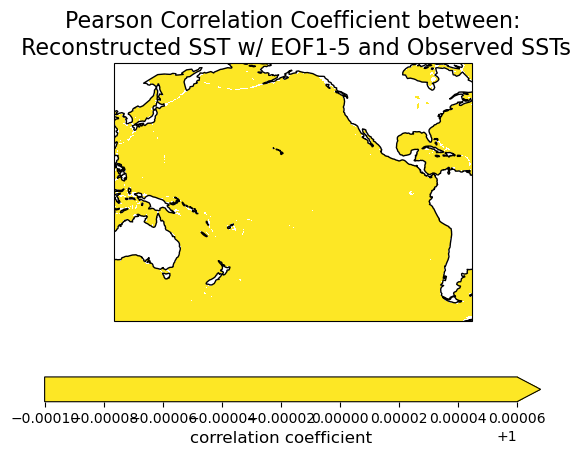

In [38]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = cc_obs.plot.contourf(ax=ax, add_colorbar=False, vmin=.9, vmax=1, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('Pearson Correlation Coefficient between:\n Reconstructed SST w/ EOF1-5 and Observed SSTs', fontsize=16)
plt.show()

# 6) Map of Pearson's CC between:

(a) SST Reconstructed using EOF 1 and (b) Monthly mean detrended, deseasonalized, and standardized anomaly of total column water vapor

... don't mask over land!

See anything interesting?

Detailed Directions:

Compute EOFs by SST and use SST EOF to compare with total column water vapor anomolies 
- Go through same process to compute SST anomolies but for water vapor
- Reconstructed SST anomolies (X) and water vapor anomolies (Y)
- Calculate CC at each point and plot it on a map

Note: EOFs allow us to discriminate between different physical forcings

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


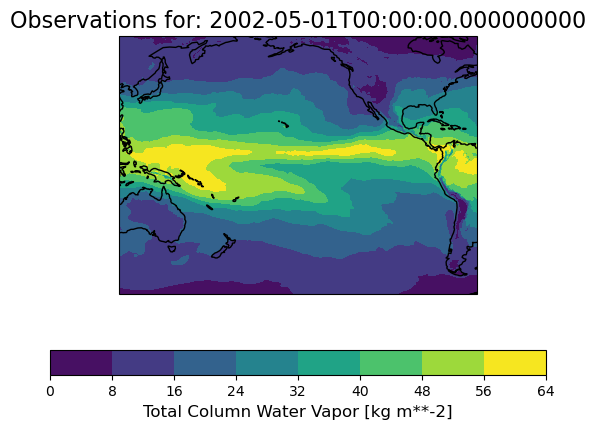

In [39]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = ds.tcwv[280,:,:].plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('Total Column Water Vapor [kg m**-2]', fontsize=12)
ax.set_title('Observations for: '+str(ds.valid_time.values[280]), fontsize=16)
plt.show()

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


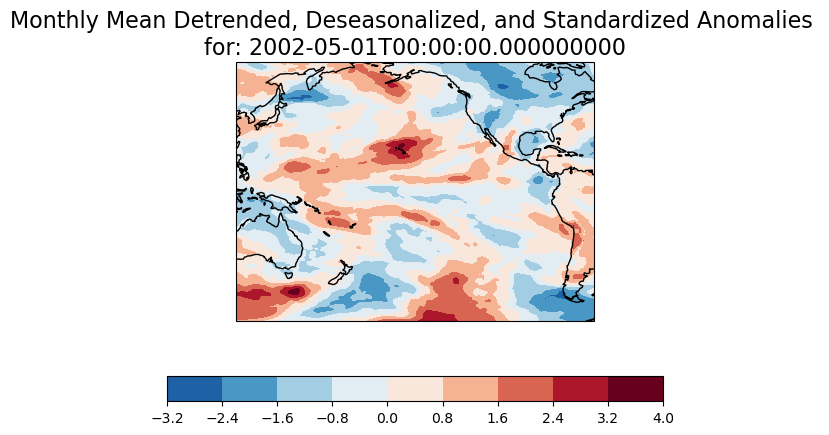

In [40]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = z.tcwv[280,:,:].plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('', fontsize=12)
ax.set_title('Monthly Mean Detrended, Deseasonalized, and Standardized Anomalies \nfor: '+str(ds.valid_time.values[280]), fontsize=16)
plt.show()

In [41]:
reconst_z_eof1 = solver.reconstructedField(1)
reconst_z_eof1 = reconst_z_eof1.rename({'time':'valid_time'})

reconst_detr_eof1 = unpack(reconst_z_eof1, detr.mask_sst, time_dim="valid_time")
reconst_sst_eof1 = linear_retrend(ds.mask_sst, reconst_detr_eof1.mask_sst, time_dim="valid_time") # linearly detrended data
reconst_sst_eof1

<xarray.DataArray (valid_time: 552, latitude: 521, longitude: 721)> Size: 829MB
dask.array<astype, shape=(552, 521, 721), dtype=float32, chunksize=(1, 521, 721), chunktype=numpy.ndarray>
Coordinates:
    number      (valid_time) int64 4kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB -240.0 -239.8 -239.5 ... -60.25 -60.0
    expver      (valid_time) <U4 9kB '0001' '0001' '0001' ... '0001' '0001'
    month       (valid_time) int64 4kB 1 2 3 4 5 6 7 8 9 ... 5 6 7 8 9 10 11 12

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


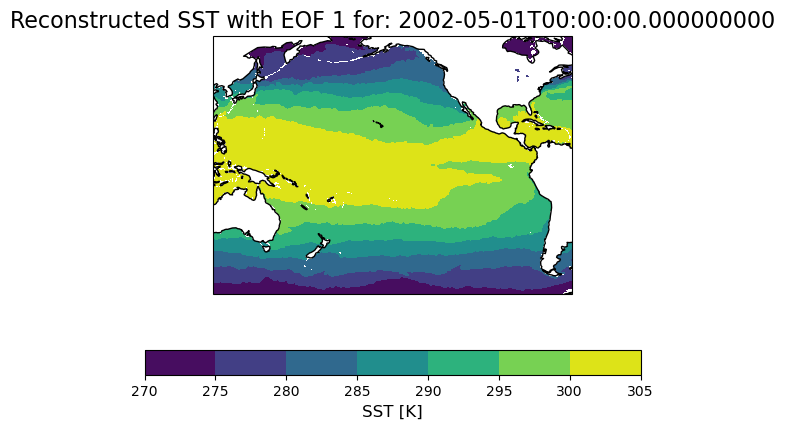

In [42]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = reconst_sst_eof1[280,:,:].plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('SST [K]', fontsize=12)
ax.set_title('Reconstructed SST with EOF 1 for: '+str(reconst_sst.valid_time.values[280]), fontsize=16)
plt.show()

In [43]:
cc_eof1_wv = xr.corr(reconst_sst_eof1, z.tcwv, dim='valid_time')

When we plot the correlation coefficient between the reconstructed SSTs using EOF1 and the detrended, deseasonalized, and standardized monthly mean total column water vapor anomlies, there are large positive correlations in regions with warmer SST temperatures. This means that there is likely a strong relationships between warmer SST temperatures and higher amounts of total column water vapor. This makes sense because if the water is warmer, then the air above is likely warmer and can hold more water vapor.

/data/keeling/a/kheimes2/miniconda3/envs/xarray-climate/lib/python3.13/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


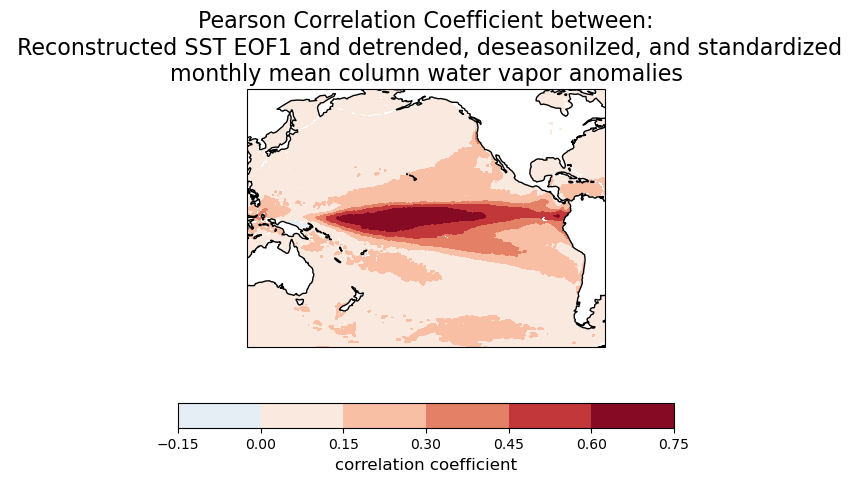

In [44]:
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=190))
fill = cc_eof1_wv.plot.contourf(ax=ax, add_colorbar=False, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE, color='k', edgecolor='k')
cb = plt.colorbar(fill, orientation='horizontal')
cb.set_label('correlation coefficient', fontsize=12)
ax.set_title('Pearson Correlation Coefficient between:\n Reconstructed SST EOF1 and detrended, deseasonilzed, and standardized\nmonthly mean column water vapor anomalies', fontsize=16)
plt.show()